**# AI Healthcare Assistant**

An educational machine learning project that explores diabetes outcome classification using Python and scikit-learn.

**Disclaimer:** This project is for educational purposes only and is not a medical diagnosis tool.


In [ ]:
print("AI Healthcare Assistant - Project Started")

AI Healthcare Assistant - Project Started


In [ ]:
import pandas as pd

print("Pandas successfully imported!")

Pandas successfully imported!


## 1. Dataset and Libraries

This project uses a publicly available diabetes dataset containing 768 records and 9 columns.

**Libraries used:**

* Pandas — data loading and analysis
* NumPy — numerical operations
* Matplotlib — data visualization
* Scikit-learn — preprocessing, model training and evaluation
* Gradio — interactive web interface

**Target column:** `Outcome` (0 or 1)


In [ ]:
import pandas as pd

url = "https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully!
Rows: 768
Columns: 9


In [ ]:
print(df.head())

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  


In [ ]:
print(df.columns)

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')


In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB
None


In [ ]:
print(df.isnull().sum())

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [ ]:
print(df.describe())

       Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
count   768.000000  768.000000     768.000000     768.000000  768.000000   
mean      3.845052  120.894531      69.105469      20.536458   79.799479   
std       3.369578   31.972618      19.355807      15.952218  115.244002   
min       0.000000    0.000000       0.000000       0.000000    0.000000   
25%       1.000000   99.000000      62.000000       0.000000    0.000000   
50%       3.000000  117.000000      72.000000      23.000000   30.500000   
75%       6.000000  140.250000      80.000000      32.000000  127.250000   
max      17.000000  199.000000     122.000000      99.000000  846.000000   

              BMI  DiabetesPedigreeFunction         Age     Outcome  
count  768.000000                768.000000  768.000000  768.000000  
mean    31.992578                  0.471876   33.240885    0.348958  
std      7.884160                  0.331329   11.760232    0.476951  
min      0.000000                  

In [ ]:
print(df["Outcome"].value_counts())

Outcome
0    500
1    268
Name: count, dtype: int64


In [ ]:
print(df["Outcome"].value_counts(normalize=True) * 100)

Outcome
0    65.104167
1    34.895833
Name: proportion, dtype: float64


In [ ]:
print((df == 0).sum())

Pregnancies                 111
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                     500
dtype: int64


## 2. Data Cleaning and Preprocessing

The dataset was inspected for missing values and suspicious zero values in selected medical measurement columns.

* Zero values in Glucose, BloodPressure, SkinThickness, Insulin, and BMI were treated as missing values.
* Missing feature values were handled using median imputation.
* The target column, `Outcome`, was kept unchanged.
* The preprocessing pipeline uses training data to learn imputation and scaling parameters, helping prevent data leakage.


In [ ]:
import numpy as np

df_clean = df.copy()

columns_to_clean = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

df_clean[columns_to_clean] = df_clean[columns_to_clean].replace(0, np.nan)

print(df_clean.isnull().sum())

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


In [ ]:
for column in columns_to_clean:
    df_clean[column] = df_clean[column].fillna(df_clean[column].median())

print(df_clean.isnull().sum())

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


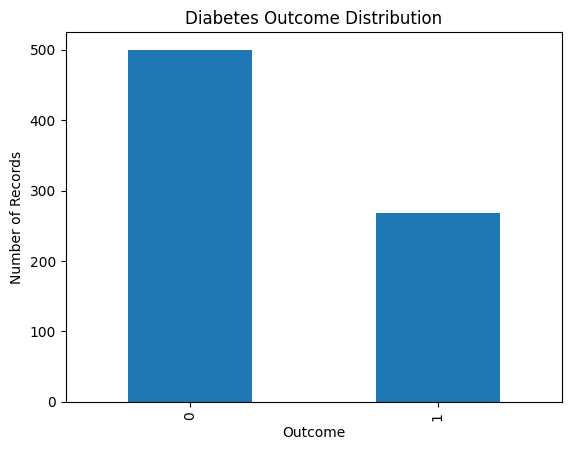

In [ ]:
import matplotlib.pyplot as plt

df_clean["Outcome"].value_counts().plot(kind="bar")

plt.title("Diabetes Outcome Distribution")
plt.xlabel("Outcome")
plt.ylabel("Number of Records")
plt.show()

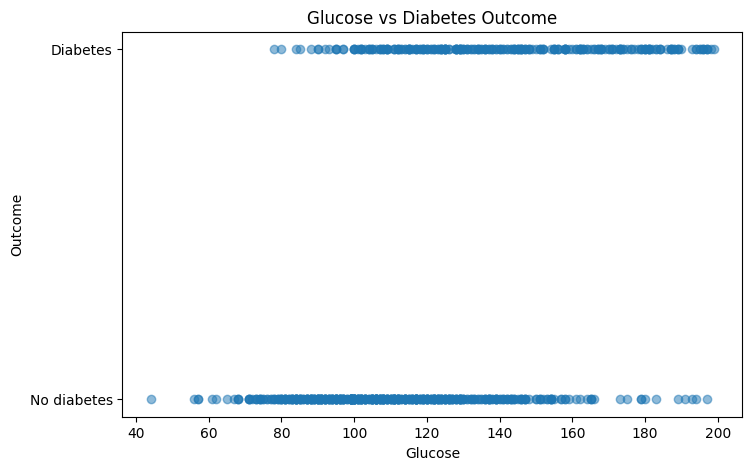

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df_clean["Glucose"],
    df_clean["Outcome"],
    alpha=0.5
)

plt.title("Glucose vs Diabetes Outcome")
plt.xlabel("Glucose")
plt.ylabel("Outcome")

plt.yticks([0, 1], ["No diabetes", "Diabetes"])

plt.show()

In [ ]:
X = df_clean.drop("Outcome", axis=1)
y = df_clean["Outcome"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (768, 8)
y shape: (768,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training data: (614, 8)
Testing data: (154, 8)
Training target: (614,)
Testing target: (154,)


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Original dataset se features aur target
X_raw = df.drop("Outcome", axis=1)
y_raw = df["Outcome"]

# Suspicious zero values ko missing values maana
columns_to_clean = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

X_raw[columns_to_clean] = X_raw[columns_to_clean].replace(0, np.nan)

# Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X_raw,
    y_raw,
    test_size=0.2,
    random_state=42,
    stratify=y_raw
)

# ML Pipeline
model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])

print("Pipeline created successfully!")

Pipeline created successfully!


## 3. Model Training and Evaluation

A Logistic Regression model was trained using the training dataset.

The dataset was split into training and testing sets using an 80:20 ratio, with stratification to preserve the target-class distribution.

The model was evaluated using:

* Accuracy
* Confusion Matrix
* Precision
* Recall
* F1-score

These metrics help assess the model's performance on unseen test data. Accuracy alone is not sufficient to evaluate a healthcare-related classification model.


In [ ]:
model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [ ]:
y_pred = model.predict(X_test)

print("Predictions generated successfully!")
print(y_pred[:20])

Predictions generated successfully!
[1 0 0 0 0 0 0 1 0 1 0 0 0 0 0 0 1 0 1 0]


## 4. Results and Model Performance

The Logistic Regression model achieved approximately **70.78% accuracy** on the test dataset.

The model was also evaluated using a confusion matrix, precision, recall, and F1-score.

The results show that the model's performance is limited, particularly in identifying the diabetes class. Further improvements and testing would be needed before considering any real-world application.

**Disclaimer:** These results are for educational purposes only and are not suitable for medical decision-making.



In [ ]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")

Model Accuracy: 0.7077922077922078
Accuracy Percentage: 70.77922077922078 %


Confusion Matrix:
[[82 18]
 [27 27]]


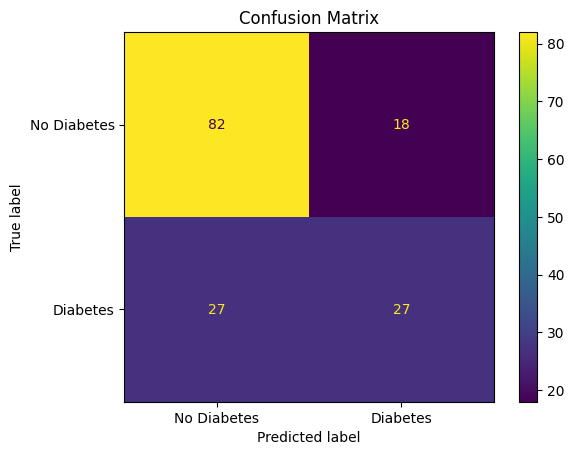

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Diabetes", "Diabetes"]
)

disp.plot()
plt.title("Confusion Matrix")
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=["No Diabetes", "Diabetes"]
))

              precision    recall  f1-score   support

 No Diabetes       0.75      0.82      0.78       100
    Diabetes       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154



In [ ]:
!pip install gradio

## 5. Interactive Gradio Application

A Gradio interface was created to let users enter the eight model features and receive an educational model output.

**Important:** This prototype is not a medical diagnosis tool and should not be used to make medical decisions.



In [ ]:
import gradio as gr

def predict_diabetes(
    pregnancies,
    glucose,
    blood_pressure,
    skin_thickness,
    insulin,
    bmi,
    diabetes_pedigree,
    age
):
    input_data = [[
        pregnancies,
        glucose,
        blood_pressure,
        skin_thickness,
        insulin,
        bmi,
        diabetes_pedigree,
        age
    ]]

    prediction = model.predict(input_data)[0]

    if prediction == 1:
        return "Higher Risk Category"
    else:
        return "Lower Risk Category"


print("Prediction function created successfully!")

Prediction function created successfully!


In [ ]:
import gradio as gr

app = gr.Interface(
    fn=predict_diabetes,
    inputs=[
        gr.Number(label="Pregnancies"),
        gr.Number(label="Glucose"),
        gr.Number(label="Blood Pressure"),
        gr.Number(label="Skin Thickness"),
        gr.Number(label="Insulin"),
        gr.Number(label="BMI"),
        gr.Number(label="Diabetes Pedigree Function"),
        gr.Number(label="Age")
    ],
    outputs=gr.Textbox(label="AI Result"),
    title="AI Healthcare Assistant",
    description="Educational ML prototype — not a medical diagnosis tool."
)

print("Gradio interface created successfully!")

Gradio interface created successfully!


In [ ]:
app.launch(share=True, debug=True, show_error=True)

NameError: name 'app' is not defined